# Task 2 — Next-Day Fire-Spread: Ablations & Evaluation (Student 4 / Zohid)

**Self-contained Colab notebook** for the *temporal* tensors. All logic is
inlined — you only need the tensors on Google Drive.

## Task & data
- Tensors: `tensors/<split>/<fire_id>.npz` with `fire_masks (N,H,W)`,
  `weather (N,6,H,W)`, `terrain (3,H,W)`; split in `tensors/sample_index.csv`.
- Window W: X = days `[i..i+W-1]`, **Y = fire_masks[i+W]** (next-day mask).

## The key modeling decision
Masks are **cumulative** and ~97-99% of next-day burned pixels are already
burned at day t. So a *persistence* prediction (next-day = today) scores ~0.98
full-extent IoU while predicting **zero spread**. We therefore predict the
**new growth** (pixels *unburned at t* that ignite at t+1) and score **growth
IoU/F1** over the unburned region. The spread signal for an unburned pixel comes
from **burning neighbors**, so each input day contributes a neighbor-burned-
fraction feature. Persistence (growth IoU = 0) is the must-beat reference.

Rules: split reused unchanged (event-level); scaler fit on **train only**;
**test** opened only for the final table; report IoU/F1 (never accuracy).

## 1. Install deps & mount Drive

In [ ]:
import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    !pip install -q scikit-learn xgboost scipy
    from google.colab import drive; drive.mount('/content/drive')
print('IN_COLAB =', IN_COLAB)

Mounted at /content/drive
IN_COLAB = True


## 2. Config + load split index from Drive

In [ ]:
import csv, json, time
from pathlib import Path
import numpy as np

# >>> EDIT to your tensors folder on Drive (contains train/ val/ test/ + sample_index.csv) <<<
TENSOR_DIR = Path('/content/drive/MyDrive/bigdata/Dataset/tensors')
WINDOW = 4
RADII  = (2, 8)            # neighbor-fraction windows: 5x5 and 17x17 px
WEATHER_VARS = ['temperature_2m','relative_humidity_pct','wind_speed_ms',
                'wind_dir_deg','surface_pressure','total_precipitation']
TERRAIN_BANDS = ['elevation_m','slope_deg','aspect_deg']
MODALITIES = ('fire','weather','terrain','combined')

def load_index():
    with open(TENSOR_DIR/'sample_index.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        for k in ('n_fire_days','n_samples','height','width','weather_offset'):
            if r.get(k,'') != '': r[k] = int(r[k])
    return rows
INDEX = load_index()

# Drop 1 corrupted + 7 empty (MODIS-miss, zero burned px) fires from the health scan.
# Re-upload 20777134.npz to Drive to restore it; the 7 empties have no fire to learn.
DROP = {'20777134',
        '21804884','21889953','21998287','23036806','23036871','24332760','24332801'}
INDEX = [r for r in INDEX if r['fire_id'] not in DROP]

def split_fires(s): return [r for r in INDEX if r['split']==s]

# leakage guard
seen={}
for r in INDEX:
    assert r['fire_id'] not in seen or seen[r['fire_id']]==r['split'], 'leakage!'
    seen[r['fire_id']]=r['split']
print({s: len(split_fires(s)) for s in ('train','val','test')}, '— pruned', len(DROP), 'fires')

{'train': 89, 'val': 20, 'test': 20} — pruned 8 fires


## 3. Loader: per-fire series, neighbor features, growth dataset

In [ ]:
from scipy.ndimage import uniform_filter

# Spatial downsample. MODIS fire labels are ~500 m, so 30 m is ~16x oversampled;
# STRIDE=4 -> 120 m loses little and runs ~16x faster. Set STRIDE=1 for full res.
# (If you build the downsampled cache below, that cell sets STRIDE=1 since the
#  cached files are already downsampled.)
STRIDE = 4

def fire_path(r):
    p = Path(r.get('tensor_file',''))
    return p if p.exists() else TENSOR_DIR/r['split']/(r['fire_id']+'.npz')

def load_series(r):
    # NOTE: the .npz files are saved with np.savez_compressed, so mmap does NOT
    # work — accessing z['weather'] decompresses the whole array. We downsample
    # and COPY immediately, then close, so only the small array stays in RAM.
    try:
        z = np.load(fire_path(r))
        sl = slice(None, None, STRIDE)
        out = {'fire_masks': np.ascontiguousarray(z['fire_masks'][:, sl, sl]),
               'weather':    np.ascontiguousarray(z['weather'][:, :, sl, sl]),
               'terrain':    np.ascontiguousarray(z['terrain'][:, sl, sl])}
        z.close()
        return out
    except Exception as e:
        print('  [skip] ' + r['fire_id'] + ' [' + r['split'] + ']: ' + type(e).__name__ + ' (corrupted .npz)')
        return None

def neighbor_fraction(mask2d, radius):
    return uniform_filter(mask2d.astype('float32'), size=2*radius+1, mode='constant')

def feature_names(window, modality='combined'):
    n=[]; uf=modality in('fire','combined'); uw=modality in('weather','combined'); ut=modality in('terrain','combined')
    for d in range(window):
        lag=window-1-d
        if uf:
            for r in RADII: n.append(f'firefrac_r{r}_lag{lag}')
        if uw:
            for v in WEATHER_VARS: n.append(f'{v}_lag{lag}')
    if ut: n += list(TERRAIN_BANDS)
    return n

def _wfeats(series, i, window, modality, sel, nf_cache=None):
    fm=series['fire_masks']; uf=modality in('fire','combined'); uw=modality in('weather','combined'); ut=modality in('terrain','combined')
    cols=[]
    for d in range(i, i+window):
        if uf:
            maps = nf_cache[d] if nf_cache is not None else [neighbor_fraction(np.asarray(fm[d]), r).reshape(-1) for r in RADII]
            for arr in maps: cols.append(arr[sel])
        if uw:
            wd=np.asarray(series['weather'][d]).reshape(6,-1)
            for v in range(6): cols.append(wd[v][sel])
    if ut:
        tr=np.asarray(series['terrain']).reshape(3,-1)
        for b in range(3): cols.append(tr[b][sel])
    return np.stack(cols,1).astype('float32')

def build_dataset(rows, window=WINDOW, modality='combined', max_pos=8000, neg_ratio=4.0,
                  seed=42, idx=False, max_fires=None):
    rng=np.random.default_rng(seed); Xs=[]; ys=[]; fs=[]
    use_fire = modality in ('fire','combined')
    if max_fires: rows = rows[:max_fires]            # quick first pass
    for fi,r in enumerate(rows):
        s=load_series(r)
        if s is None: continue
        fm=s['fire_masks']; nd=fm.shape[0]
        # compute each day's neighbor map ONCE per fire (not per window)
        nf_cache = {d:[neighbor_fraction(np.asarray(fm[d]), rad).reshape(-1) for rad in RADII]
                    for d in range(nd)} if use_fire else None
        for i in range(nd-window):
            mt=np.asarray(fm[i+window-1]).reshape(-1).astype(bool)
            yn=np.asarray(fm[i+window]).reshape(-1).astype(bool)
            region=~mt; pos=np.where(region & yn)[0]
            if pos.size==0: continue
            neg=np.where(region & ~yn)[0]
            if pos.size>max_pos: pos=rng.choice(pos,max_pos,replace=False)
            nn=min(neg.size,int(neg_ratio*pos.size))
            if nn>0: neg=rng.choice(neg,nn,replace=False)
            sel=np.concatenate([pos,neg]); X=_wfeats(s,i,window,modality,sel,nf_cache)
            v=np.isfinite(X).all(1); X=X[v]
            lab=np.zeros(sel.size,'uint8'); lab[:pos.size]=1; lab=lab[v]
            Xs.append(X); ys.append(lab)
            if idx: fs.append(np.full(lab.size,fi,'int32'))
        del s                                        # free the fire before the next one
    if not Xs:
        nf=len(feature_names(window,modality)); E=(np.empty((0,nf),'float32'),np.empty((0,),'uint8'))
        return (*E,np.empty((0,),'int32')) if idx else E
    X=np.concatenate(Xs); y=np.concatenate(ys)
    return (X,y,np.concatenate(fs)) if idx else (X,y)

class Standardizer:
    def fit(s,X): s.m=np.nanmean(X,0); v=np.nanstd(X,0); v[v==0]=1; s.s=v; return s
    def transform(s,X): return (X-s.m)/s.s

In [ ]:
# === Run ONCE: build a small DOWNSAMPLED cache so everything fits in RAM ===
# The raw .npz are saved with savez_compressed, so loading a big fire decompresses
# several GB of weather and OOMs Colab. This writes a ~16x-smaller copy per fire to
# DS_DIR (skipping the few fires too big to decompress safely), then re-points the
# notebook at the cache. It is idempotent — already-cached fires are reused, so
# re-running is fast.
import gc, csv

DS_DIR     = TENSOR_DIR.parent / 'tensors_ds'   # cache folder on Drive
STRIDE_PRE = 4                                   # downsample factor for the cache
BUDGET_GB  = 3.0                                 # skip fires whose weather would exceed this

for sp in ('train','val','test'):
    (DS_DIR/sp).mkdir(parents=True, exist_ok=True)

cache_rows, skipped = [], []
for r in INDEX:
    H, W, N = int(r['height']), int(r['width']), int(r['n_fire_days'])
    est_gb = N*6*H*W*4/1e9                        # decompressed weather size
    out = DS_DIR/r['split']/(r['fire_id']+'.npz')
    if out.exists():
        cache_rows.append({**r, 'tensor_file': str(out)}); continue
    if est_gb > BUDGET_GB:
        skipped.append((r['fire_id'], f'{est_gb:.1f}GB')); continue
    try:
        z = np.load(fire_path(r)); sl = slice(None, None, STRIDE_PRE)
        fm = np.ascontiguousarray(z['fire_masks'][:, sl, sl])
        wx = np.ascontiguousarray(z['weather'][:, :, sl, sl])
        tr = np.ascontiguousarray(z['terrain'][:, sl, sl]); z.close()
        np.savez_compressed(out, fire_masks=fm, weather=wx, terrain=tr)
        cache_rows.append({**r, 'tensor_file': str(out),
                           'height': fm.shape[1], 'width': fm.shape[2]})
        del fm, wx, tr; gc.collect()
    except Exception as e:
        skipped.append((r['fire_id'], type(e).__name__))
        print('  cache FAIL', r['fire_id'], type(e).__name__)

with open(DS_DIR/'sample_index.csv', 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=list(cache_rows[0].keys())); w.writeheader(); w.writerows(cache_rows)

# Re-point the notebook at the cache. Cached files are ALREADY downsampled -> STRIDE=1.
TENSOR_DIR = DS_DIR
STRIDE = 1
INDEX = cache_rows
print('cache ready:', len(cache_rows), 'fires |',
      {s: len(split_fires(s)) for s in ('train','val','test')})
print('skipped (too big / error):', skipped)

cache ready: 122 fires | {'train': 85, 'val': 18, 'test': 19}
skipped (too big / error): [('20778140', '4.3GB'), ('20778186', '3.6GB'), ('24332647', '6.2GB'), ('24332732', '3.3GB'), ('24332763', '3.0GB'), ('24332939', '6.6GB'), ('24461899', '3.4GB')]


## 4. Metrics (growth) + model factory

In [ ]:
EPS=1e-9
def counts(yt,yp):
    yt=np.asarray(yt).astype(bool).ravel(); yp=np.asarray(yp).astype(bool).ravel()
    return int((yt&yp).sum()),int((~yt&yp).sum()),int((yt&~yp).sum())
def iou(yt,yp):
    tp,fp,fn=counts(yt,yp); d=tp+fp+fn; return tp/d if d>0 else float('nan')
def f1(yt,yp):
    tp,fp,fn=counts(yt,yp); p=tp/(tp+fp+EPS); r=tp/(tp+fn+EPS); return 2*p*r/(p+r+EPS)
def by_fire(yt,yp,fidx,fn):
    per={int(f):fn(yt[fidx==f],yp[fidx==f]) for f in np.unique(fidx)}
    vals=np.array([v for v in per.values() if np.isfinite(v)])
    return float(vals.mean()) if vals.size else float('nan')
def persistence_full_iou(fm, window=WINDOW):
    fm=np.asarray(fm); v=[iou(fm[i+window],fm[i+window-1]) for i in range(fm.shape[0]-window)]
    v=[x for x in v if np.isfinite(x)]; return float(np.mean(v)) if v else float('nan')

def get_classifier(seed=42):
    try:
        from xgboost import XGBClassifier
        return XGBClassifier(n_estimators=300,max_depth=6,learning_rate=0.1,subsample=0.8,
            colsample_bytree=0.8,n_jobs=-1,tree_method='hist',objective='binary:logistic',
            eval_metric='logloss',random_state=seed),'xgboost'
    except Exception:
        from sklearn.ensemble import HistGradientBoostingClassifier
        return HistGradientBoostingClassifier(max_iter=300,random_state=seed),'sklearn.HGB'

## 5. Sanity check — one fire, growth fraction

In [ ]:
r0=split_fires('test')[0]; s=load_series(r0); fm=s['fire_masks']
print(r0['fire_id'], 'fire_masks', fm.shape, '| weather', s['weather'].shape, '| terrain', s['terrain'].shape)
print('persistence full-extent IoU:', round(persistence_full_iou(fm),3), '(inflated — why we score growth)')

20777508 fire_masks (7, 391, 515) | weather (7, 6, 391, 515) | terrain (3, 391, 515)
persistence full-extent IoU: 0.937 (inflated — why we score growth)


## 6. Ablation A — temporal window W = 1 / 2 / 4 (eval on val)

In [ ]:
def train_eval(window, modality, seed=42):
    Xtr,ytr=build_dataset(split_fires('train'),window,modality,seed=seed)
    if Xtr.shape[0]==0 or len(np.unique(ytr))<2: return {'window':window,'modality':modality,'iou':float('nan'),'f1':float('nan')}
    sc=Standardizer().fit(Xtr); clf,be=get_classifier(seed); clf.fit(sc.transform(Xtr),ytr)
    Xv,yv,fi=build_dataset(split_fires('val'),window,modality,seed=seed+1,idx=True)
    pred=clf.predict(sc.transform(Xv))
    return {'window':window,'modality':modality,'backend':be,'n_features':Xtr.shape[1],
            'iou':by_fire(yv,pred,fi,iou),'f1':by_fire(yv,pred,fi,f1)}

A=[train_eval(w,'combined') for w in (1,2,4)]
for r in A: print(f"  W={r['window']}: growth IoU={r['iou']:.3f}  F1={r['f1']:.3f}  feats={r.get('n_features')}")

  W=1: growth IoU=0.363  F1=0.507  feats=11
  W=2: growth IoU=0.392  F1=0.531  feats=19
  W=4: growth IoU=0.519  F1=0.648  feats=35


## 7. Ablation B — input modality (W=4, eval on val)

In [ ]:
B=[train_eval(4,m) for m in MODALITIES]
for r in B: print(f"  {r['modality']:9s}: growth IoU={r['iou']:.3f}  F1={r['f1']:.3f}")

  fire     : growth IoU=0.575  F1=0.695
  weather  : growth IoU=0.002  F1=0.005
  terrain  : growth IoU=0.000  F1=0.000
  combined : growth IoU=0.519  F1=0.648


## 8. Plot ablations

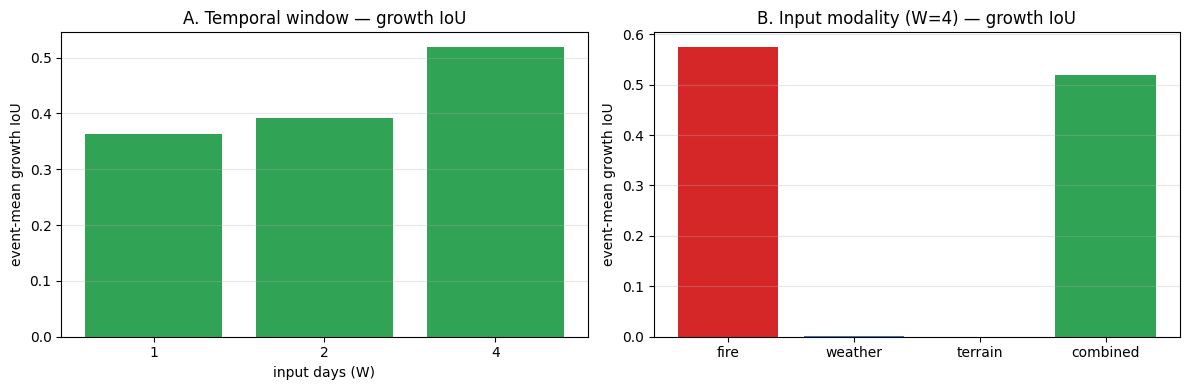

In [ ]:
import matplotlib.pyplot as plt
OUT=Path('outputs/ablations'); OUT.mkdir(parents=True,exist_ok=True)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].bar([str(r['window']) for r in A],[r['iou'] for r in A],color='#31a354')
ax[0].set_title('A. Temporal window — growth IoU'); ax[0].set_xlabel('input days (W)')
ax[1].bar([r['modality'] for r in B],[r['iou'] for r in B],color=['#d62728','#3182bd','#8c6d31','#31a354'])
ax[1].set_title('B. Input modality (W=4) — growth IoU')
for a in ax: a.set_ylabel('event-mean growth IoU'); a.grid(axis='y',alpha=0.3)
plt.tight_layout(); plt.savefig(OUT/'ablation_growth_iou.png',dpi=120,bbox_inches='tight'); plt.show()

## 9. Final comparison on TEST (growth, event-level)
Train the pixel growth model on `train`; score it + the persistence baseline on
the locked test fires. Teammates add rows via `predict_window` + `RESULTS`.

In [10]:
# Train pixel growth model (combined, W=4)
Xtr,ytr=build_dataset(split_fires('train'),WINDOW,'combined',seed=42)
scaler=Standardizer().fit(Xtr); clf,backend=get_classifier(42); clf.fit(scaler.transform(Xtr),ytr)

def predict_window(fm_win, wx_win, terr, chunk=500000):
    H,W=fm_win.shape[-2:]; mt=fm_win[-1].astype(bool); out=mt.copy().ravel()
    region=np.where(~mt.ravel())[0]; series={'fire_masks':fm_win,'weather':wx_win,'terrain':terr}
    for s0 in range(0,region.size,chunk):
        sel=region[s0:s0+chunk]; X=_wfeats(series,0,WINDOW,'combined',sel)
        v=np.isfinite(X).all(1); pr=np.zeros(sel.size,bool)
        if v.any(): pr[v]=clf.predict(scaler.transform(X[v])).astype(bool)
        out[sel]=pr
    return out.reshape(H,W)

def eval_on_test(predict_fn):
    iou_pf=[]; f1_pf=[]; full_pf=[]
    for r in split_fires('test'):
        s=load_series(r)
        if s is None: continue
        fm=np.asarray(s['fire_masks']); nd=fm.shape[0]
        gt=[]; gp=[]; fu=[]
        for i in range(nd-WINDOW):
            mt=fm[i+WINDOW-1].astype(bool); yn=fm[i+WINDOW].astype(bool)
            pred=predict_fn(fm[i:i+WINDOW],np.asarray(s['weather'][i:i+WINDOW]),np.asarray(s['terrain'])).astype(bool)
            reg=~mt; gt.append((yn&reg).ravel()); gp.append((pred&reg).ravel()); fu.append(iou(yn,pred))
        if not gt: continue
        GT=np.concatenate(gt); GP=np.concatenate(gp)
        if GT.sum()==0: continue
        iou_pf.append(iou(GT,GP)); f1_pf.append(f1(GT,GP)); full_pf.append(np.nanmean(fu))
    m=lambda x: float(np.nanmean(x)) if x else float('nan')
    return {'growth_iou':m(iou_pf),'growth_f1':m(f1_pf),'full_extent_iou':m(full_pf),'n':len(iou_pf)}

persist=eval_on_test(lambda fm,wx,tr: fm[-1])
pixel  =eval_on_test(predict_window)
print('Persistence : growth IoU=%.3f  full=%.3f'%(persist['growth_iou'],persist['full_extent_iou']))
print('Pixel model : growth IoU=%.3f  F1=%.3f  full=%.3f  [%s]'%(pixel['growth_iou'],pixel['growth_f1'],pixel['full_extent_iou'],backend))

Persistence : growth IoU=0.000  full=0.830
Pixel model : growth IoU=0.107  F1=0.184  full=0.704  [xgboost]


In [11]:
RESULTS=[
  {'model':'Persistence (baseline)','owner':'reference', **persist},
  {'model':'Pixel growth model (Student 4)','owner':'Student 4', **pixel},
  # teammates: append {'model':..,'owner':..,'growth_iou':..,'growth_f1':..,'full_extent_iou':..}
]
def fmt(x):
    return f'{x:.3f}' if isinstance(x,(int,float)) and x==x else '—'
L=['# Task 2 — Model Comparison (next-day growth, test set)','',
   '| Model | Owner | Growth IoU | Growth F1 | Full-extent IoU |',
   '|-------|-------|-----------:|----------:|----------------:|']
for r in RESULTS:
    L.append(f"| {r['model']} | {r.get('owner','')} | {fmt(r.get('growth_iou'))} | {fmt(r.get('growth_f1'))} | {fmt(r.get('full_extent_iou'))} |")
Path('reports').mkdir(exist_ok=True)
Path('reports/task2_model_comparison.md').write_text('\n'.join(L),encoding='utf-8')
print('\n'.join(L))

# Task 2 — Model Comparison (next-day growth, test set)

| Model | Owner | Growth IoU | Growth F1 | Full-extent IoU |
|-------|-------|-----------:|----------:|----------------:|
| Persistence (baseline) | reference | 0.000 | 0.000 | 0.830 |
| Pixel growth model (Student 4) | Student 4 | 0.107 | 0.184 | 0.704 |


## 10. Growth map for one test fire (TP / FP / FN of new spread)

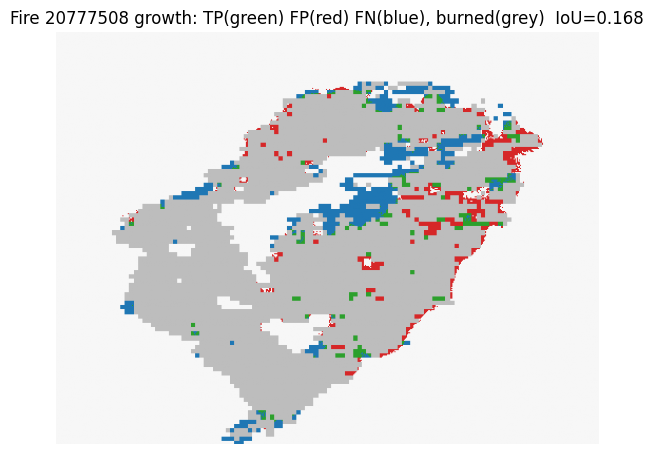

In [12]:
from matplotlib.colors import ListedColormap
r=split_fires('test')[0]; s=load_series(r); fm=np.asarray(s['fire_masks'])
i=0  # first window
mt=fm[i+WINDOW-1].astype(bool); yn=fm[i+WINDOW].astype(bool)
pred=predict_window(fm[i:i+WINDOW],np.asarray(s['weather'][i:i+WINDOW]),np.asarray(s['terrain'])).astype(bool)
reg=~mt; gt=yn&reg; gp=pred&reg
viz=np.zeros(fm.shape[1:],'int8'); viz[mt]=4  # already burned (context)
viz[gt&gp]=1; viz[gp&~gt]=2; viz[gt&~gp]=3
cmap=ListedColormap(['#f7f7f7','#2ca02c','#d62728','#1f77b4','#bdbdbd'])
plt.figure(figsize=(7,6)); plt.imshow(viz,cmap=cmap,vmin=0,vmax=4)
plt.title(f"Fire {r['fire_id']} growth: TP(green) FP(red) FN(blue), burned(grey)  IoU={iou(gt,gp):.3f}"); plt.axis('off')
Path('outputs').mkdir(exist_ok=True)
plt.savefig(f"outputs/growth_map_{r['fire_id']}.png",dpi=120,bbox_inches='tight'); plt.show()